# Actividad 2 · Mi primer pronóstico ARIMA

**Módulo 5: Econometría y Forecasting con IA — CEC EPN / Banco Central del Ecuador**  
**Día 3 · Unidad 2 · Trabajo individual · 40 minutos · 20 puntos**

Este notebook ya funciona completo. Tu trabajo:

1. **Ejecuta** todas las celdas en orden (menú *Kernel → Restart & Run All*).
2. **Anota** el pronóstico de los próximos tres meses y los errores MAE y RMSE de la versión original.
3. En la celda marcada **PARÁMETRO A MODIFICAR**, cambia `ORDEN = (1, 1, 1)` por `ORDEN = (2, 1, 1)` y vuelve a ejecutar desde esa celda hacia abajo.
4. **Compara** pronósticos, intervalos y errores.
5. **Responde** las cuatro preguntas en las celdas de texto del final.

Puedes usar un agente de IA para entender una línea de código o corregir un error. Si lo usas, anota en una línea qué le preguntaste (celda final). Las respuestas deben basarse en **tus** resultados y estar escritas con tus palabras.

## La serie

Usamos la **inflación mensual del Ecuador** (INEC), desde enero de 2005: la variación porcentual del IPC respecto al mes anterior. Es la misma serie de los Días 1 a 3.

## Preparación: ejecuta estas dos celdas primero

Funcionan igual en tu computador (Anaconda + Jupyter) y en Google Colab:

1. **Instalación de librerías.** `%pip install` instala lo que falte; si ya está instalado, no hace nada.
2. **Datos.** Si encuentra la carpeta `datos/` del repositorio, la usa. Si no la encuentra (por ejemplo en Colab), descarga los archivos desde GitHub.

Si Colab pide *"Restart session"* después de instalar, acéptalo y vuelve a ejecutar desde aquí.

In [ ]:
# 1) Librerías de este notebook (en local no reinstala lo que ya tienes; en Colab instala lo que falte)
%pip install -q numpy pandas matplotlib statsmodels scikit-learn

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error, mean_squared_error
import warnings
warnings.filterwarnings('ignore')

In [ ]:
# 2) Datos: usa la carpeta 'datos' del repositorio si existe; si no (Colab), descarga los archivos de GitHub
from pathlib import Path
import urllib.request

URL_DATOS = 'https://raw.githubusercontent.com/jonarosero/modulo5_econometria_forecasting_ia/main/datos'
ARCHIVOS = [          # archivos que usa ESTE notebook
    'series_economicas.csv',
]

# Buscamos el ARCHIVO (no solo la carpeta): Jupyter abierto en la raíz -> 'datos'; en notebooks/ -> '../datos'
DATA_DIR = next((c for c in [Path('datos'), Path('../datos')] if (c / ARCHIVOS[0]).exists()), None)

if DATA_DIR is None:                       # no está en este computador: lo descargamos (caso Colab)
    DATA_DIR = Path('datos')
    for archivo in ARCHIVOS:
        destino = DATA_DIR / archivo
        destino.parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(f'{URL_DATOS}/{archivo}', destino)
        print('Descargado:', archivo)

print('Usando datos desde:', DATA_DIR.resolve())

In [4]:
series = pd.read_csv(DATA_DIR / 'series_economicas.csv', parse_dates=['fecha'], index_col='fecha').asfreq('MS')
y = series['ipc_var_mensual'].loc['2005':].dropna()

print(f'{len(y)} meses, de {y.index.min():%b %Y} a {y.index.max():%b %Y}')
y.tail()

260 meses, de Jan 2005 a Aug 2026


fecha
2026-04-01    0.525567
2026-05-01   -0.621261
2026-06-01    0.788722
2026-07-01   -0.089334
2026-08-01    0.042938
Freq: MS, Name: ipc_var_mensual, dtype: float64

## Paso 1 · Mirar la serie

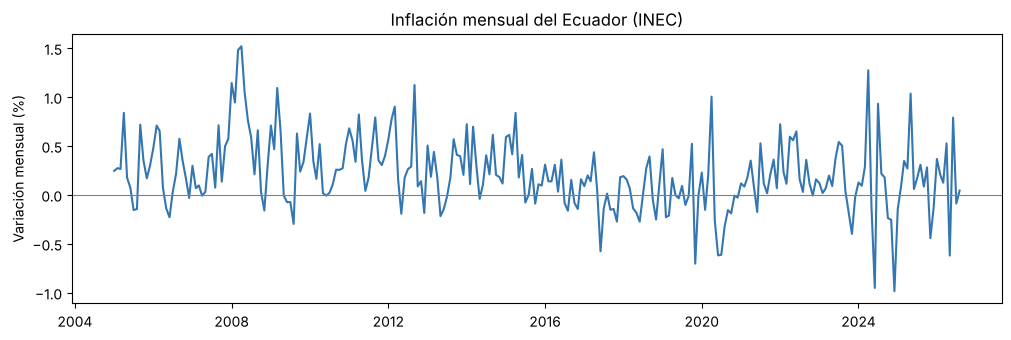

In [5]:
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(y, color='#3476B1')
ax.axhline(0, color='gray', linewidth=0.8)
ax.set_ylabel('Variación mensual (%)')
ax.set_title('Inflación mensual del Ecuador (INEC)')
plt.show()

## Paso 2 · PARÁMETRO A MODIFICAR

`ORDEN` es la tupla $(p, d, q)$ del modelo ARIMA (Día 2, parte 7):

- $p$: rezagos de la serie (parte autorregresiva);
- $d$: número de diferencias;
- $q$: rezagos de los choques (parte de medias móviles).

**Versión original:** `(1, 1, 1)`. **Versión modificada:** `(2, 1, 1)`.

In [6]:
# ======================= PARÁMETRO A MODIFICAR =======================
ORDEN = (1, 1, 1)
# =====================================================================

HORIZONTE = 3   # meses a pronosticar
print('Modelo: ARIMA', ORDEN)

Modelo: ARIMA (1, 1, 1)


## Paso 3 · Evaluar el modelo en 2025–2026

Estimamos los parámetros con los datos hasta diciembre de 2024 y pronosticamos **a un paso** cada mes de enero 2025 a agosto 2026 (Día 3, parte 5).

ARIMA(1, 1, 1) · MAE = 0.308 · RMSE = 0.429 (puntos porcentuales)


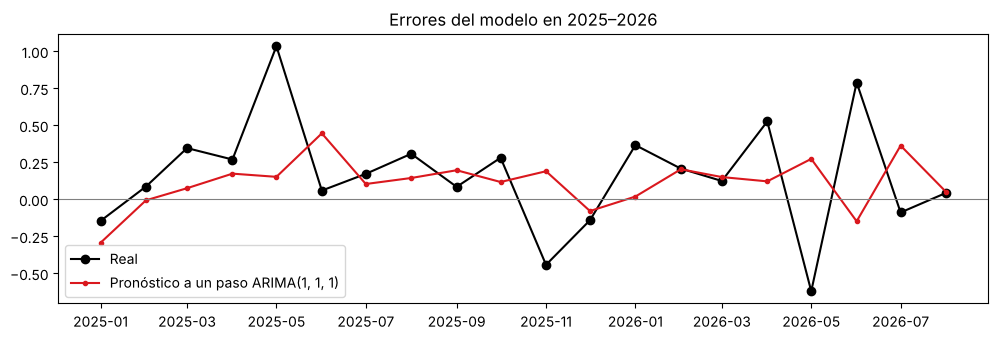

In [7]:
modelo_eval = ARIMA(y.loc[:'2024-12'], order=ORDEN).fit()
pred_test = modelo_eval.apply(y).predict(start='2025-01-01', end=y.index.max())
real_test = y.loc['2025-01-01':]

mae = mean_absolute_error(real_test, pred_test)
rmse = np.sqrt(mean_squared_error(real_test, pred_test))

print(f'ARIMA{ORDEN} · MAE = {mae:.3f} · RMSE = {rmse:.3f} (puntos porcentuales)')

fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(real_test, color='black', marker='o', label='Real')
ax.plot(pred_test, color='#DA181E', marker='.', label=f'Pronóstico a un paso ARIMA{ORDEN}')
ax.axhline(0, color='gray', linewidth=0.8)
ax.set_title('Errores del modelo en 2025–2026')
ax.legend()
plt.show()

## Paso 4 · Pronosticar los próximos tres meses

Reestimamos con **toda** la serie y pronosticamos con intervalos del 95 %.

In [8]:
modelo_final = ARIMA(y, order=ORDEN).fit()
pron = modelo_final.get_forecast(steps=HORIZONTE)

tabla = pd.DataFrame({
    'pronostico_%': pron.predicted_mean,
    'inferior_95_%': pron.conf_int(alpha=0.05).iloc[:, 0],
    'superior_95_%': pron.conf_int(alpha=0.05).iloc[:, 1],
}).round(3)
print(modelo_final.params.round(3).to_string())
tabla

ar.L1     0.275
ma.L1    -0.957
sigma2    0.114


,pronostico_%,inferior_95_%,superior_95_%
2026-09-01,0.098,-0.564,0.761
2026-10-01,0.114,-0.582,0.809
2026-11-01,0.118,-0.583,0.819


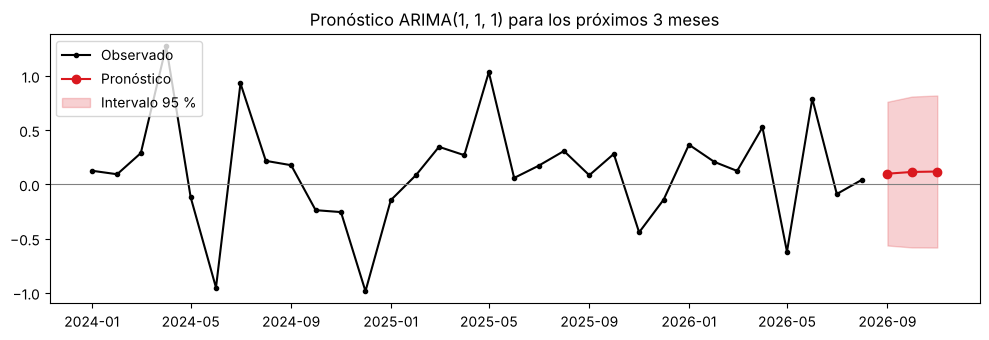

In [9]:
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(y.loc['2024':], color='black', marker='o', markersize=3, label='Observado')
ax.plot(tabla['pronostico_%'], color='#DA181E', marker='o', label='Pronóstico')
ax.fill_between(tabla.index, tabla['inferior_95_%'], tabla['superior_95_%'], color='#DA181E', alpha=0.2, label='Intervalo 95 %')
ax.axhline(0, color='gray', linewidth=0.8)
ax.set_title(f'Pronóstico ARIMA{ORDEN} para los próximos {HORIZONTE} meses')
ax.legend(loc='upper left')
plt.show()

## Paso 5 · Preguntas

**Antes de responder**, ejecuta el notebook con las dos versiones de `ORDEN` y anota los resultados de ambas.

| | ARIMA(1, 1, 1) | ARIMA(2, 1, 1) |
|---|---|---|
| MAE 2025–2026 | | |
| RMSE 2025–2026 | | |
| Pronóstico mes 1 | | |
| Intervalo 95 % mes 1 | | |

### Pregunta 1 · ¿Qué se pronosticó?
Indica la variable, la unidad, el horizonte y los valores obtenidos con el modelo original.

*Tu respuesta:*

### Pregunta 2 · ¿Cómo cambió el resultado al modificar el parámetro?
Compara pronósticos e intervalos de las dos versiones, con cifras.

*Tu respuesta:*

### Pregunta 3 · ¿Qué muestran los errores?
Interpreta MAE y RMSE de ambas versiones en la unidad de la serie y di cuál tuvo menor error en 2025–2026.

*Tu respuesta:*

### Pregunta 4 · ¿Qué limitaciones observas?
Menciona al menos dos.

*Tu respuesta:*

### Uso de IA (si aplica)
*Qué le preguntaste al agente, en una línea:*